# Etapa 2 — Pré-processamento dos dados

- **Amostra:** um pedido entregue (uma linha por `order_id`).
- **Alvo (`y`):** dias entre a compra e a entrega ao cliente, em valor fracionado.
- **Momento da previsão:** no ato da compra — só entram variáveis conhecidas nesse instante.

In [1]:
# Imports e constantes usados em todo o notebook.
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ))
from app.features import (
    COLUNAS_ASSIMETRICAS,
    COLUNAS_BINARIAS,
    COLUNAS_CATEGORICAS,
    COLUNAS_NUMERICAS,
    carregar_tabelas,
    colunas_features,
    construir_dataset,
    criar_preprocessador,
)

DATA_DIR = RAIZ / 'data' / 'olist'
SEED = 42
LIMITE_CAUDA_DIAS = 60

pd.set_option('display.float_format', '{:.2f}'.format)

## 1. Dados e valores faltantes

Tabelas usadas: `orders`, `order_items`, `products`, `customers`, `sellers` e `geolocation`.
`order_reviews` fica de fora (só existe depois da entrega, vazaria o alvo), assim como `order_payments`
e a tradução de categorias.

In [2]:
# Carregar as tabelas e ver onde há valores faltantes antes de qualquer junção.
tabelas = carregar_tabelas(DATA_DIR)

linhas = []
for nome, tabela in tabelas.items():
    nulos = tabela.isna().sum()
    for coluna, n in nulos[nulos > 0].items():
        linhas.append({'tabela': nome, 'linhas': len(tabela), 'coluna': coluna,
                       'nulos': n, '% nulos': 100 * n / len(tabela)})

print({nome: tabela.shape for nome, tabela in tabelas.items()})
pd.DataFrame(linhas)

{'orders': (99441, 8), 'order_items': (112650, 7), 'products': (32951, 9), 'customers': (99441, 5), 'sellers': (3095, 4), 'geolocation': (1000163, 5)}


,tabela,linhas,coluna,nulos,% nulos
0,orders,99441,order_approved_at,160,0.16
1,orders,99441,order_delivered_carrier_date,1783,1.79
2,orders,99441,order_delivered_customer_date,2965,2.98
3,products,32951,product_category_name,610,1.85
4,products,32951,product_name_lenght,610,1.85
5,products,32951,product_description_lenght,610,1.85
6,products,32951,product_photos_qty,610,1.85
7,products,32951,product_weight_g,2,0.01
8,products,32951,product_length_cm,2,0.01
9,products,32951,product_height_cm,2,0.01


As datas faltantes de `orders` são de pedidos não entregues (ou sem data de entrega), que saem no filtro.
Em `products`, faltam categoria (610 produtos), peso e dimensões (2 produtos); além disso, 4 produtos têm
peso igual a zero, que tratamos como ausente. `customers` e `sellers` não têm nulos, mas parte dos CEPs
não aparece em `geolocation` — isso é tratado na construção do dataset.

## 2. Engenharia de atributos

`construir_dataset` (em `app/features.py`) faz, nesta ordem:

1. **Filtro:** `order_status == 'delivered'` e data de entrega preenchida.
2. **Alvo e prazo estimado:** `y` e `prazo_estimado` em dias fracionados. O prazo estimado fica **fora de X** e será
   usado na etapa 5 como termo de comparação.
3. **Geolocalização:** remove pontos fora do Brasil e resume cada prefixo de CEP pela **mediana** de latitude e longitude
   (sem isso a junção multiplicaria os pedidos). CEP sem geolocalização recebe a mediana do **estado**.
4. **Agregação por pedido:** `n_itens`, `n_vendedores`, `preco_total`, `frete_total`, `peso_total_g` e `volume_max_cm3`.
   Com mais de um vendedor, a coordenada do vendedor é a **média** dos vendedores do pedido; `seller_state` e `categoria`
   vêm do primeiro item.
5. **Distância e calendário:** `dist_km` (Haversine), `mesmo_estado`, `mes`, `dia_semana`, `hora`.

Todas as junções usam `validate=` para garantir que nenhuma multiplique linhas.

In [3]:
# Construir uma linha por pedido entregue e conferir unicidade e imputações de coordenadas.
df = construir_dataset(tabelas)

print(f'Linhas: {len(df)} | order_id único: {df["order_id"].is_unique}')
print(f'Pedidos com coordenada do cliente imputada pelo estado: {df["coord_cliente_imputada"].sum()}')
print(f'Pedidos com coordenada de vendedor imputada pelo estado: {df["coord_vendedor_imputada"].sum()}')
print(f'Pedidos com dist_km calculada a partir de alguma coordenada imputada: {df["coord_imputada"].sum()}')
print(f'Pedidos com mais de um item: {(df["n_itens"] > 1).mean():.1%} | '
      f'com mais de um vendedor: {(df["n_vendedores"] > 1).sum()} ({(df["n_vendedores"] > 1).mean():.1%})')
df.head()

Linhas: 96470 | order_id único: True
Pedidos com coordenada do cliente imputada pelo estado: 265
Pedidos com coordenada de vendedor imputada pelo estado: 217
Pedidos com dist_km calculada a partir de alguma coordenada imputada: 481
Pedidos com mais de um item: 10.0% | com mais de um vendedor: 1275 (1.3%)


,order_id,order_purchase_timestamp,y,prazo_estimado,frete_total,preco_total,peso_total_g,volume_max_cm3,dist_km,n_itens,...,mes,dia_semana,hora,mesmo_estado,customer_state,seller_state,categoria,coord_cliente_imputada,coord_vendedor_imputada,coord_imputada
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,8.44,15.54,8.72,29.99,500.00,1976.00,18.68,1,...,10,0,10,1,SP,SP,utilidades_domesticas,0,0,0
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,13.78,19.14,22.76,118.70,400.00,4693.00,861.04,1,...,7,1,20,0,BA,SP,perfumaria,0,0,0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,9.39,26.64,19.22,159.90,420.00,9576.00,514.55,1,...,8,2,8,0,GO,SP,automotivo,0,0,0
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,13.21,26.19,27.20,45.00,450.00,6000.00,1821.80,1,...,11,5,19,0,RN,MG,pet_shop,0,0,0
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2.87,12.11,8.72,19.90,250.00,11475.00,29.59,1,...,2,1,21,1,SP,SP,papelaria,0,0,0


## 3. Limpeza e cauda longa

A base final tem apenas pedidos entregues com data de entrega. O alvo tem cauda longa: alguns pedidos levam
mais de 100 dias. Esses casos são eventos excepcionais (extravio, greve, problema do vendedor) que não dá para
prever com a informação da hora da compra.

**Decisão do grupo:** remover pedidos com `y > 60` **somente do treino**, depois da divisão; o teste mantém todos
os pedidos e as métricas são reportadas duas vezes ("todos" e "até 60 dias"). O alvo continua em dias, sem log.

In [4]:
# Registrar o tamanho da base e o perfil do alvo, que justificam o corte da cauda.
total_pedidos = len(tabelas['orders'])
nao_entregues = (tabelas['orders']['order_status'] != 'delivered').sum()
entregues_sem_data = total_pedidos - nao_entregues - len(df)
n_validos = len(df)
n_excluidos = total_pedidos - n_validos
motivo = f'{nao_entregues} com status diferente de delivered e {entregues_sem_data} entregues sem data de entrega'
print(f'Base: {n_validos} pedidos válidos; {n_excluidos} excluídos ({motivo}).')

y = df['y']
acima_limite = y > LIMITE_CAUDA_DIAS
print(f'Pedidos acima de {LIMITE_CAUDA_DIAS} dias: {acima_limite.sum()} ({acima_limite.mean():.2%}); '
      f'acima de 100 dias: {(y > 100).sum()}')
y.describe(percentiles=[0.5, 0.9, 0.99]).to_frame('y (dias)').T

Base: 96470 pedidos válidos; 2971 excluídos (2963 com status diferente de delivered e 8 entregues sem data de entrega).
Pedidos acima de 60 dias: 306 (0.32%); acima de 100 dias: 64


,count,mean,std,min,50%,90%,99%,max
y (dias),96470.00,12.56,9.55,0.53,10.22,23.10,46.05,209.63


In [5]:
# Testar empiricamente a decisão sobre a cauda: treino completo x treino sem >60 dias x alvo log1p, mesmo teste.
X_todo = df[colunas_features()]
y_todo = df['y']

resultados = []
for semente in [SEED, SEED + 1, SEED + 2]:
    X_tr, X_te, y_tr, y_te = train_test_split(X_todo, y_todo, test_size=0.2, random_state=semente)
    dentro_limite = y_tr <= LIMITE_CAUDA_DIAS

    variantes = {
        'treino completo': (X_tr, y_tr, False),
        f'treino sem >{LIMITE_CAUDA_DIAS} dias': (X_tr[dentro_limite], y_tr[dentro_limite], False),
        'alvo log1p': (X_tr, y_tr, True),
    }
    for nome, (X_fit, y_fit, usar_log) in variantes.items():
        regressor = HistGradientBoostingRegressor(random_state=SEED)
        if usar_log:
            regressor = TransformedTargetRegressor(regressor=regressor, func=np.log1p, inverse_func=np.expm1)
        modelo = Pipeline([('prep', criar_preprocessador()), ('modelo', regressor)])
        modelo.fit(X_fit, y_fit)
        previsto = modelo.predict(X_te)
        resultados.append({'variante': nome, 'divisão': semente,
                           'MAE': mean_absolute_error(y_te, previsto),
                           'RMSE': root_mean_squared_error(y_te, previsto)})

teste_cauda = pd.DataFrame(resultados).groupby('variante', sort=False)[['MAE', 'RMSE']].mean()
teste_cauda.style.format('{:.3f}')

,MAE,RMSE
variante,,
treino completo,4.698,7.614
treino sem >60 dias,4.628,7.614
alvo log1p,4.462,7.760


**Leitura:** Com o mesmo teste (média de 3 divisões aleatórias), remover os pedidos acima de 60 dias do treino
reduziu o MAE (4,70 → 4,63 dias) e deixou o RMSE igual (7,61 nos dois casos). O alvo em `log1p` tem o menor MAE (4,46),
mas o pior RMSE (7,76), porque passa a subestimar os pedidos longos. Os resultados sustentam a decisão do grupo:
**treino sem a cauda e alvo em dias**. Nestas três divisões o corte da cauda
empatou no RMSE em vez de melhorá-lo levemente. Com as divisões `random_state` 0, 1 e 2, o mesmo pipeline reproduz os
valores de referência (treino completo: MAE 4,72 / RMSE 7,89; sem a cauda: MAE 4,64 / RMSE 7,86), então o empate é
variação entre divisões, não uma diferença no código.

## 4. Divisão treino/teste e pipeline

A divisão 80/20 (`random_state=42`) acontece **antes** de ajustar qualquer imputer, scaler ou encoder.
O pré-processamento fica dentro de um `ColumnTransformer`:

- **Numéricas assimétricas** (`frete_total`, `preco_total`, `peso_total_g`, `volume_max_cm3`): mediana → `log1p` → `StandardScaler`.
- **Numéricas restantes** (distância, itens, vendedores, coordenadas, calendário): mediana → `StandardScaler`.
- **Binária** (`mesmo_estado`): sem transformação.
- **Categóricas** (`customer_state`, `seller_state`, `categoria`): `OneHotEncoder(handle_unknown='ignore', min_frequency=100)`,
  que agrupa categorias com menos de 100 pedidos em "infrequente".

In [6]:
# Dividir antes de qualquer ajuste e cortar a cauda só no treino.
treino, teste = train_test_split(df, test_size=0.2, random_state=SEED)
treino_filtrado = treino[treino['y'] <= LIMITE_CAUDA_DIAS]

print(f'Treino: {len(treino)} pedidos -> {len(treino_filtrado)} após remover '
      f'{len(treino) - len(treino_filtrado)} pedidos com y > {LIMITE_CAUDA_DIAS} dias')
print(f'Teste: {len(teste)} pedidos (todos mantidos; {(teste["y"] > LIMITE_CAUDA_DIAS).sum()} acima de {LIMITE_CAUDA_DIAS} dias)')

Treino: 77176 pedidos -> 76927 após remover 249 pedidos com y > 60 dias
Teste: 19294 pedidos (todos mantidos; 57 acima de 60 dias)


In [7]:
# Teste rápido: a categoria do produto melhora o baseline? Usa uma validação tirada do treino (o teste fica intocado).
sub_treino, validacao = train_test_split(treino_filtrado, test_size=0.2, random_state=SEED)
erros_categoria = {}
for usar_categoria in [True, False]:
    colunas = colunas_features(usar_categoria)
    modelo = Pipeline([('prep', criar_preprocessador(usar_categoria)),
                       ('modelo', HistGradientBoostingRegressor(random_state=SEED))])
    modelo.fit(sub_treino[colunas], sub_treino['y'])
    previsto = modelo.predict(validacao[colunas])
    erros_categoria['com categoria' if usar_categoria else 'sem categoria'] = {
        'MAE': mean_absolute_error(validacao['y'], previsto),
        'RMSE': root_mean_squared_error(validacao['y'], previsto),
    }

USAR_CATEGORIA = erros_categoria['com categoria']['RMSE'] < erros_categoria['sem categoria']['RMSE']
print(f'Usar categoria: {USAR_CATEGORIA}')
pd.DataFrame(erros_categoria).T

Usar categoria: True


,MAE,RMSE
com categoria,4.46,6.50
sem categoria,4.47,6.51


In [8]:
# Ajustar o pré-processador só no treino e conferir as formas antes e depois da transformação.
FEATURES = colunas_features(USAR_CATEGORIA)
X_treino, y_treino = treino_filtrado[FEATURES], treino_filtrado['y']
X_teste, y_teste = teste[FEATURES], teste['y']
prazo_estimado_teste = teste['prazo_estimado']  # guardado para a comparação da etapa 5, fora de X

preprocessador = criar_preprocessador(USAR_CATEGORIA)
X_treino_t = preprocessador.fit_transform(X_treino)
X_teste_t = preprocessador.transform(X_teste)

print(f'X_treino: {X_treino.shape} -> {X_treino_t.shape}')
print(f'X_teste:  {X_teste.shape} -> {X_teste_t.shape}')
print(f'Nulos após o pré-processamento: treino {np.isnan(X_treino_t).sum()}, teste {np.isnan(X_teste_t).sum()}')
nomes_saida = preprocessador.get_feature_names_out()
print(f'Colunas geradas por grupo: '
      f'{pd.Series([n.split("__")[0] for n in nomes_saida]).value_counts().to_dict()}')

X_treino: (76927, 18) -> (76927, 105)
X_teste:  (19294, 18) -> (19294, 105)
Nulos após o pré-processamento: treino 0, teste 0
Colunas geradas por grupo: {'categoricas': 90, 'numericas': 10, 'assimetricas': 4, 'binarias': 1}


## 5. Resumo das features

In [9]:
# Tabela-resumo de todas as features selecionadas (exigida pelo enunciado), com os nulos imputados no treino.
# Tipo e tratamento vêm dos grupos de app/features.py, então a tabela sempre reflete o pipeline de verdade.
grupos = [
    (COLUNAS_ASSIMETRICAS, 'numérica', 'mediana + log1p + padronização'),
    (COLUNAS_NUMERICAS, 'numérica', 'mediana + padronização'),
    (COLUNAS_BINARIAS, 'binária', 'nenhum'),
    (COLUNAS_CATEGORICAS, 'categórica', 'one-hot (min_frequency=100)'),
]
tipo_e_tratamento = {}
for colunas_do_grupo, tipo, tratamento in grupos:
    for coluna in colunas_do_grupo:
        tipo_e_tratamento[coluna] = (tipo, tratamento)

descricao = {
    'frete_total': ('order_items', 'soma do frete dos itens'),
    'preco_total': ('order_items', 'soma do preço dos itens'),
    'peso_total_g': ('products', 'soma do peso dos itens (peso 0 = ausente)'),
    'volume_max_cm3': ('products', 'maior volume entre os itens (comp. x alt. x larg.)'),
    'dist_km': ('geolocation', 'Haversine entre vendedor (média) e cliente'),
    'n_itens': ('order_items', 'quantidade de itens do pedido'),
    'n_vendedores': ('order_items', 'quantidade de vendedores distintos'),
    'customer_lat': ('geolocation + customers', 'mediana do CEP do cliente'),
    'customer_lng': ('geolocation + customers', 'mediana do CEP do cliente'),
    'seller_lat': ('geolocation + sellers', 'mediana do CEP; média entre vendedores'),
    'seller_lng': ('geolocation + sellers', 'mediana do CEP; média entre vendedores'),
    'mes': ('orders', 'mês da compra'),
    'dia_semana': ('orders', 'dia da semana da compra (0 = segunda)'),
    'hora': ('orders', 'hora da compra'),
    'mesmo_estado': ('customers + sellers', '1 se estado do cliente = estado do vendedor'),
    'customer_state': ('customers', 'estado do cliente'),
    'seller_state': ('sellers', 'estado do vendedor do primeiro item'),
    'categoria': ('products', 'categoria do primeiro item'),
}
coordenadas = ['customer_lat', 'customer_lng', 'seller_lat', 'seller_lng', 'dist_km']

linhas = []
for coluna in FEATURES:
    tipo, tratamento = tipo_e_tratamento[coluna]
    origem, construcao = descricao[coluna]
    if coluna in coordenadas:
        imputada = f'{treino_filtrado["coord_imputada"].sum()} pedidos (mediana do estado, antes do split)'
    elif coluna == 'categoria':
        imputada = f'{(treino_filtrado["categoria"] == "desconhecida").sum()} pedidos ("desconhecida")'
    else:
        n_nulos = X_treino[coluna].isna().sum()
        imputada = f'{n_nulos} pedidos (mediana do treino)' if n_nulos > 0 else 'não'
    linhas.append({'feature': coluna, 'tipo': tipo, 'origem': origem, 'construção': construcao,
                   'tratamento': tratamento, 'imputada no treino': imputada})

pd.set_option('display.max_colwidth', None)
pd.DataFrame(linhas)

,feature,tipo,origem,construção,tratamento,imputada no treino
0,frete_total,numérica,order_items,soma do frete dos itens,mediana + log1p + padronização,não
1,preco_total,numérica,order_items,soma do preço dos itens,mediana + log1p + padronização,não
2,peso_total_g,numérica,products,soma do peso dos itens (peso 0 = ausente),mediana + log1p + padronização,20 pedidos (mediana do treino)
3,volume_max_cm3,numérica,products,maior volume entre os itens (comp. x alt. x larg.),mediana + log1p + padronização,14 pedidos (mediana do treino)
4,dist_km,numérica,geolocation,Haversine entre vendedor (média) e cliente,mediana + padronização,"393 pedidos (mediana do estado, antes do split)"
5,n_itens,numérica,order_items,quantidade de itens do pedido,mediana + padronização,não
6,n_vendedores,numérica,order_items,quantidade de vendedores distintos,mediana + padronização,não
7,customer_lat,numérica,geolocation + customers,mediana do CEP do cliente,mediana + padronização,"393 pedidos (mediana do estado, antes do split)"
8,customer_lng,numérica,geolocation + customers,mediana do CEP do cliente,mediana + padronização,"393 pedidos (mediana do estado, antes do split)"
9,seller_lat,numérica,geolocation + sellers,mediana do CEP; média entre vendedores,mediana + padronização,"393 pedidos (mediana do estado, antes do split)"


In [10]:
# O que ficou de fora e por quê.
excluidas = [
    ('order_reviews (nota e comentário)', 'só existe depois da entrega: vazaria o alvo'),
    ('order_approved_at, order_delivered_carrier_date', 'acontecem depois da compra: não são conhecidas no momento da previsão'),
    ('prazo_estimado (order_estimated_delivery_date)', 'guardado fora de X para comparar com o modelo na etapa 5'),
    ('order_payments', 'fora de escopo por decisão do grupo'),
    ('product_category_name_translation', 'só traduz a categoria; não acrescenta informação'),
    ('cluster de geolocalização', 'testado pelo grupo: igual aos estados (linear) ou pior que as coordenadas (árvores)'),
    ('cidade, nome/descrição/fotos do produto', 'alta cardinalidade ou sem relação esperada com o transporte'),
]
if not USAR_CATEGORIA:
    excluidas.append(('categoria', 'sem ganho no teste rápido da seção 4'))
pd.DataFrame(excluidas, columns=['item', 'motivo'])

,item,motivo
0,order_reviews (nota e comentário),só existe depois da entrega: vazaria o alvo
1,"order_approved_at, order_delivered_carrier_date",acontecem depois da compra: não são conhecidas no momento da previsão
2,prazo_estimado (order_estimated_delivery_date),guardado fora de X para comparar com o modelo na etapa 5
3,order_payments,fora de escopo por decisão do grupo
4,product_category_name_translation,só traduz a categoria; não acrescenta informação
5,cluster de geolocalização,testado pelo grupo: igual aos estados (linear) ou pior que as coordenadas (árvores)
6,"cidade, nome/descrição/fotos do produto",alta cardinalidade ou sem relação esperada com o transporte


## 6. Desafio real do problema

Para quantificar o desafio, usamos um **baseline rápido** — `HistGradientBoostingRegressor` com parâmetros padrão e as
features acima, treinado no treino filtrado. **Não é o modelo final** e não passa por ajuste de hiperparâmetros
(isso é da etapa 4). A referência é prever sempre a média do treino.

In [11]:
# Baseline rápido (não é o modelo final) comparado com prever sempre a média, em todos os pedidos e até 60 dias.
baseline = Pipeline([('prep', criar_preprocessador(USAR_CATEGORIA)),
                     ('modelo', HistGradientBoostingRegressor(random_state=SEED))])
baseline.fit(X_treino, y_treino)
media = DummyRegressor(strategy='mean').fit(X_treino, y_treino)

previsto_baseline = baseline.predict(X_teste)
previsto_media = media.predict(X_teste)
ate_limite = (y_teste <= LIMITE_CAUDA_DIAS).to_numpy()

metricas = []
for modelo_nome, previsto in [('prever a média', previsto_media), ('baseline HGB', previsto_baseline)]:
    for recorte_nome, mascara in [('todos os pedidos', np.ones(len(y_teste), dtype=bool)),
                                  (f'até {LIMITE_CAUDA_DIAS} dias', ate_limite)]:
        metricas.append({'modelo': modelo_nome, 'recorte do teste': recorte_nome,
                         'MAE': mean_absolute_error(y_teste[mascara], previsto[mascara]),
                         'RMSE': root_mean_squared_error(y_teste[mascara], previsto[mascara]),
                         'R²': r2_score(y_teste[mascara], previsto[mascara])})
pd.DataFrame(metricas)

,modelo,recorte do teste,MAE,RMSE,R²
0,prever a média,todos os pedidos,6.37,9.31,-0.00
1,prever a média,até 60 dias,6.18,8.41,-0.00
2,baseline HGB,todos os pedidos,4.62,7.48,0.36
3,baseline HGB,até 60 dias,4.44,6.46,0.41


In [12]:
# Peso da cauda longa no erro: quanto do erro quadrático total vem dos pedidos acima de 60 dias.
erro_quadratico = (y_teste.to_numpy() - previsto_baseline) ** 2
na_cauda = ~ate_limite
participacao_cauda = erro_quadratico[na_cauda].sum() / erro_quadratico.sum()

print(f'Pedidos do teste acima de {LIMITE_CAUDA_DIAS} dias: {na_cauda.sum()} ({na_cauda.mean():.2%})')
print(f'Participação desses pedidos no erro quadrático total: {participacao_cauda:.1%}')
print(f'Erro absoluto médio na cauda: {np.sqrt(erro_quadratico[na_cauda]).mean():.1f} dias '
      f'(contra {np.sqrt(erro_quadratico[ate_limite]).mean():.1f} no restante)')

Pedidos do teste acima de 60 dias: 57 (0.30%)
Participação desses pedidos no erro quadrático total: 25.5%
Erro absoluto médio na cauda: 64.2 dias (contra 4.4 no restante)


In [13]:
# Onde o baseline erra mais: MAE por estado do cliente e por faixa de distância.
resultado_teste = teste[['customer_state', 'dist_km', 'y']].copy()
resultado_teste['erro_abs'] = np.abs(y_teste.to_numpy() - previsto_baseline)
resultado_teste['erro_abs_media'] = np.abs(y_teste.to_numpy() - previsto_media)
faixas = [0, 100, 500, 1000, 2000, np.inf]
rotulos = ['até 100 km', '100–500 km', '500–1000 km', '1000–2000 km', 'mais de 2000 km']
resultado_teste['faixa_dist'] = pd.cut(resultado_teste['dist_km'], bins=faixas, labels=rotulos, include_lowest=True)

por_estado = resultado_teste.groupby('customer_state').agg(
    pedidos=('y', 'size'), prazo_medio=('y', 'mean'), MAE=('erro_abs', 'mean'), MAE_media=('erro_abs_media', 'mean'),
).sort_values('MAE', ascending=False)
por_distancia = resultado_teste.groupby('faixa_dist', observed=True).agg(
    pedidos=('y', 'size'), prazo_medio=('y', 'mean'), MAE=('erro_abs', 'mean'), MAE_media=('erro_abs_media', 'mean'),
)

display(por_distancia)
display(por_estado.head(10))

,pedidos,prazo_medio,MAE,MAE_media
faixa_dist,,,,
até 100 km,3684,6.53,3.07,7.17
100–500 km,7381,11.46,4.37,5.64
500–1000 km,5182,14.27,5.01,5.77
1000–2000 km,1911,17.77,5.98,7.37
mais de 2000 km,1136,20.86,7.15,9.60


,pedidos,prazo_medio,MAE,MAE_media
customer_state,,,,
RR,10,46.28,25.70,34.19
AC,9,29.51,12.46,17.75
AM,26,31.47,11.61,19.85
AL,80,24.43,8.29,12.45
RN,104,20.12,7.65,9.55
PA,189,22.81,7.56,11.36
SE,63,22.09,7.47,10.42
PI,79,18.98,7.02,8.28
PB,104,19.99,6.82,8.66


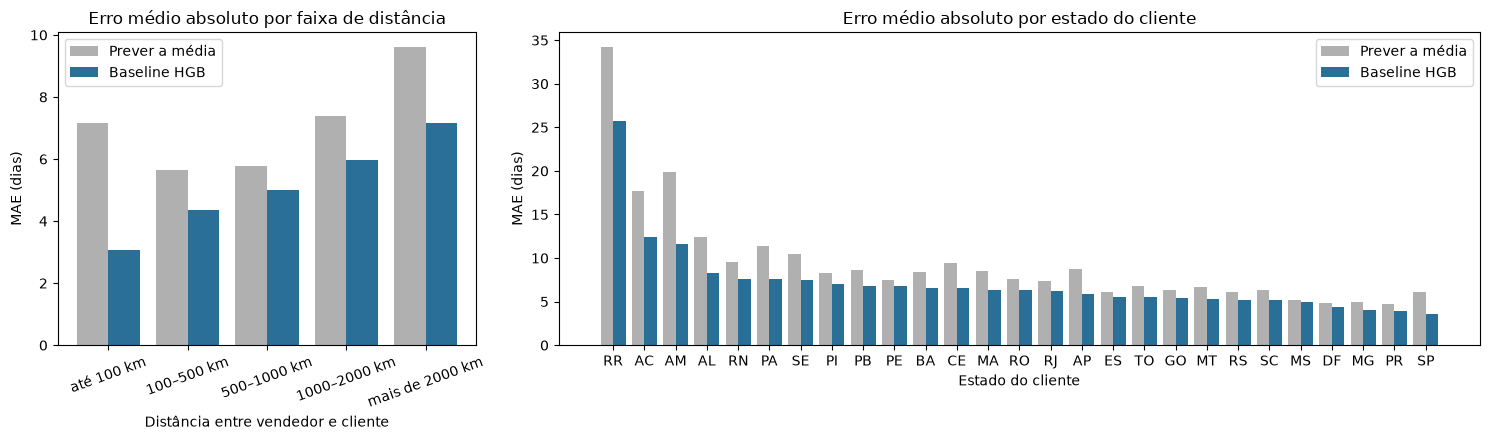

In [14]:
# Gráfico para o slide: MAE do baseline e de prever a média, por faixa de distância e por estado do cliente.
fig, eixos = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={'width_ratios': [1, 2.2]})

posicao = np.arange(len(por_distancia))
eixos[0].bar(posicao - 0.2, por_distancia['MAE_media'], width=0.4, label='Prever a média', color='#b0b0b0')
eixos[0].bar(posicao + 0.2, por_distancia['MAE'], width=0.4, label='Baseline HGB', color='#2a6f97')
eixos[0].set_xticks(posicao, por_distancia.index, rotation=20)
eixos[0].set_title('Erro médio absoluto por faixa de distância')
eixos[0].set_xlabel('Distância entre vendedor e cliente')
eixos[0].set_ylabel('MAE (dias)')
eixos[0].legend()

estados = por_estado.sort_values('MAE', ascending=False)
posicao = np.arange(len(estados))
eixos[1].bar(posicao - 0.2, estados['MAE_media'], width=0.4, label='Prever a média', color='#b0b0b0')
eixos[1].bar(posicao + 0.2, estados['MAE'], width=0.4, label='Baseline HGB', color='#2a6f97')
eixos[1].set_xticks(posicao, estados.index)
eixos[1].set_title('Erro médio absoluto por estado do cliente')
eixos[1].set_xlabel('Estado do cliente')
eixos[1].set_ylabel('MAE (dias)')
eixos[1].legend()

fig.tight_layout()
plt.show()

### Interpretação

**O desafio real:** com tudo o que se sabe no momento da compra — distância, estados, frete, peso, volume e calendário —
o baseline explica só **cerca de 36% da variância do prazo** (R² 0,36; o RMSE cai de 9,31 para 7,48 dias em relação a prever
a média; até 60 dias, R² 0,41 e RMSE 6,46). Ou seja, a maior parte da variação do prazo continua sem explicação.

- **Cauda longa:** os 57 pedidos do teste acima de 60 dias (0,30%) respondem por **25,5% do erro quadrático total**,
  com erro médio de 64 dias, contra 4,4 dias no restante.
- **Distância:** o erro cresce com a distância — MAE de 3,1 dias até 100 km contra 7,2 dias acima de 2.000 km.
- **Estados:** o erro é maior no Norte e no Nordeste (RR 25,7; AC 12,5; AM 11,6; AL 8,3 dias), onde os prazos são longos
  e há poucos pedidos para aprender (RR e AC têm cerca de 10 pedidos no teste). Chama atenção o **RJ**: 2.490 pedidos e
  MAE de 6,2 dias, quase o dobro de SP (3,5), mesmo estando perto dos vendedores.

**Hipótese:** boa parte do prazo depende de fatores que só acontecem depois da compra e não estão nos
dados da hora da previsão — quanto tempo o vendedor leva para postar, qual transportadora e modalidade são usadas e
eventos externos (greves, extravios, clima, picos como a Black Friday). Se for assim, existe um teto para o que qualquer
modelo consegue com essas variáveis, e trocar de algoritmo não resolve o problema sozinho.

**O que seria necessário para melhorar:**
- histórico do vendedor (tempo médio de postagem e de entrega), calculado só com pedidos anteriores à compra;
- transportadora e modalidade de frete;
- volume de pedidos no período (sazonalidade, Black Friday) e calendário de feriados;
- dados de rota/região mais finos que o estado (por exemplo, capital x interior).

## Conclusão

- **Base:** 96.470 pedidos entregues com data de entrega (2.971 excluídos: 2.963 não entregues e 8 entregues sem data).
- **Divisão:** 80/20 com `random_state=42`. Treino de 77.176 pedidos → 76.927 após remover 249 pedidos acima de 60 dias;
  teste com 19.294 pedidos, todos mantidos.
- **Features:** 18 (14 numéricas, 1 binária, 3 categóricas) → 105 colunas após o `ColumnTransformer`, ajustado só no treino.
- **Categoria:** mantida, com ganho pequeno na validação (RMSE 6,51 → 6,50; MAE 4,47 → 4,46).
- **Coordenadas:** 481 pedidos com coordenada imputada pela mediana do estado. A imputação usa só a tabela de geolocalização
  (não usa o alvo), por isso é feita antes da divisão.
- **Prazo estimado da Olist:** guardado fora de X, para a comparação da etapa 5.
- **Cauda:** treino sem pedidos acima de 60 dias e alvo em dias; métricas sempre em "todos os pedidos" e "até 60 dias".